**NAME - Bhushan Bhamare**\
**PRN - 202401110078**\
**BATCH - A3**


## Practical 5: Image Generation Using Pretrained Stable Diffusion

This practical explores text-to-image generation using a pretrained Stable Diffusion model. We will generate images from text prompts and examine how inference steps, guidance scale, and sampling methods affect the results.

**Aim:** To generate images from text and study the effect of inference steps, guidance scale, and sampling methods on image quality and generation time.

In [1]:
# ---------------------------------------------------------------------
# CELL 1: Install libraries (run once, then restart runtime if asked)
# ---------------------------------------------------------------------

!pip uninstall -y torchao
!pip install -q -U diffusers transformers accelerate safetensors

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


In [2]:
# ---------------------------------------------------------------------
# CELL 2: Import libraries
# ---------------------------------------------------------------------
import time                                   # to measure time taken
import torch                                  # deep learning library (runs the model)
import matplotlib.pyplot as plt               # to show images and graphs
from diffusers import (
    StableDiffusionPipeline,                  # the complete text-to-image model
    PNDMScheduler,                            # sampling method 1
    DDIMScheduler,                            # sampling method 2
    EulerDiscreteScheduler,                   # sampling method 3
    EulerAncestralDiscreteScheduler,          # sampling method 4
    DPMSolverMultistepScheduler,              # sampling method 5
)

In [3]:
# ---------------------------------------------------------------------
# CELL 3: Load the pretrained Stable Diffusion model
# ---------------------------------------------------------------------
# Use GPU if available (much faster), otherwise CPU
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

# Load the pretrained model from Hugging Face (first time = big download)
# float16 = half precision: uses less memory and runs faster on GPU
pipe = StableDiffusionPipeline.from_pretrained(
    "stable-diffusion-v1-5/stable-diffusion-v1-5",
    torch_dtype=torch.float16,
)
pipe = pipe.to(device)                        # move the model to the GPU
pipe.safety_checker = None                    # switch off NSFW filter (it can wrongly give black images)

# Save the default scheduler settings so we can build other schedulers from it
scheduler_config = pipe.scheduler.config


Using device: cuda


/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

In [4]:
# ---------------------------------------------------------------------
# CELL 4: A helper function that generates ONE image
# ---------------------------------------------------------------------
def generate(prompt, steps=30, guidance=7.5, seed=42):
    # The seed fixes the starting random noise, so results can be compared fairly
    generator = torch.Generator(device=device).manual_seed(seed)

    start = time.time()                       # start the stopwatch
    image = pipe(
        prompt,                               # text description of the image
        num_inference_steps=steps,            # number of denoising steps
        guidance_scale=guidance,              # how strongly to follow the prompt
        generator=generator,                  # fixed seed
    ).images[0]                               # the pipeline returns a list; take the first image
    seconds = time.time() - start             # stop the stopwatch

    return image, seconds


In [5]:
# ---------------------------------------------------------------------
# CELL 5: A helper function to show many images side by side
# ---------------------------------------------------------------------
def show_images(images, titles, columns=3):
    rows = (len(images) + columns - 1) // columns          # rows needed (rounded up)
    plt.figure(figsize=(5 * columns, 5 * rows))             # size of the whole figure
    for i in range(len(images)):
        plt.subplot(rows, columns, i + 1)                   # pick box number i+1 in the grid
        plt.imshow(images[i])                               # draw the image
        plt.title(titles[i])                                # write its title
        plt.axis("off")                                     # hide axis numbers
    plt.tight_layout()
    plt.show()


### Experiment 1: Basic Text-to-Image Generation

A text prompt describes the image we want the model to create. Stable Diffusion starts with random noise and gradually refines it into an image that matches the prompt. The generation time is also recorded.

  0%|          | 0/30 [00:00<?, ?it/s]

Time taken: 6.7 seconds


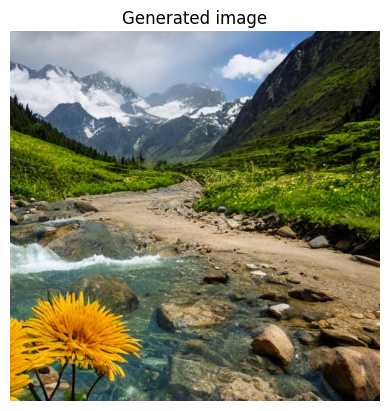

In [6]:
# ---------------------------------------------------------------------
# CELL 6: Experiment 1 - Basic text-to-image generation
# ---------------------------------------------------------------------
prompt = "a picture with clean mountains,cystal-clear rivers along with scenic flowers all these in natural light"

image, seconds = generate(prompt)             # default: 30 steps, guidance 7.5
print("Time taken:", round(seconds, 1), "seconds")
plt.imshow(image)
plt.axis("off")
plt.title("Generated image")
plt.show()

### Experiment 2: Effect of Inference Steps

Inference steps are the repeated denoising updates used to create an image. In this comparison, the prompt, guidance scale, and scheduler are kept constant while the number of steps changes. This helps show how additional steps affect image detail and generation time.

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

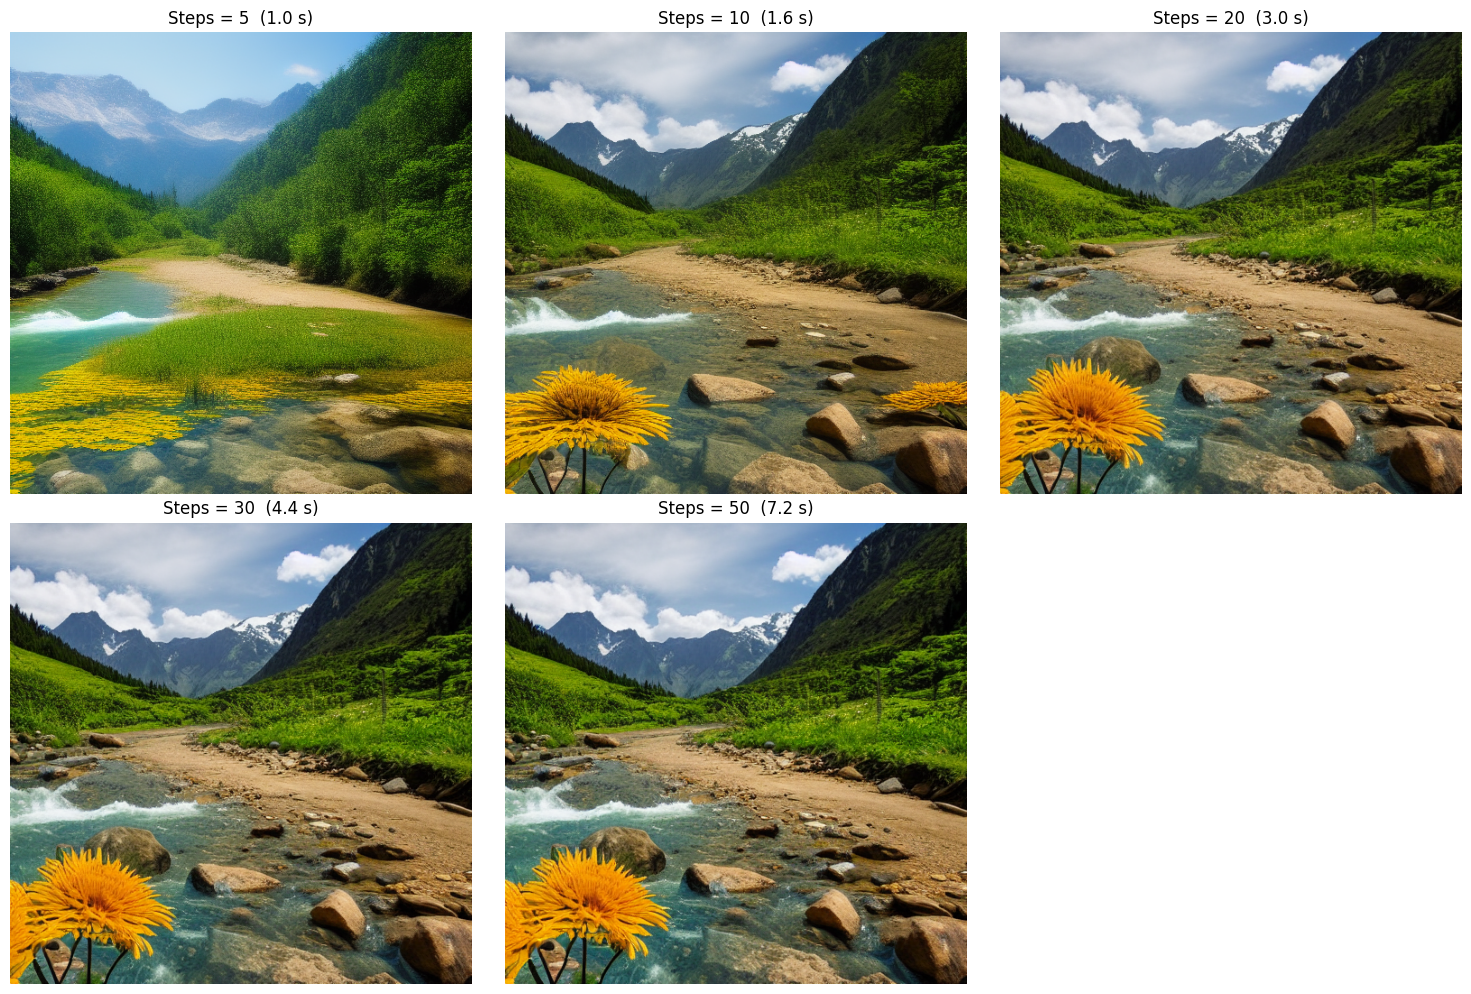

In [7]:
# ---------------------------------------------------------------------
# CELL 7: Experiment 2 - Effect of INFERENCE STEPS
# (guidance and scheduler stay the same, only steps change)
# ---------------------------------------------------------------------
# Use one fixed scheduler for this experiment
pipe.scheduler = DPMSolverMultistepScheduler.from_config(scheduler_config)

step_list = [5, 10, 20, 30, 50]
images = []
titles = []

for s in step_list:
    img, sec = generate(prompt, steps=s)      # change only the steps
    images.append(img)
    titles.append("Steps = " + str(s) + "  (" + str(round(sec, 1)) + " s)")

show_images(images, titles)

# Observation: very few steps (5) = rough/unfinished image.
# After about 20-30 steps the image hardly changes, but time keeps increasing.

### Experiment 3: Effect of Sampling Method

A scheduler determines how the model removes noise at each step. Here, the prompt, number of inference steps, and guidance scale are kept constant while the scheduler changes. Compare the resulting images and generation times to see how the sampling method affects the output.

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

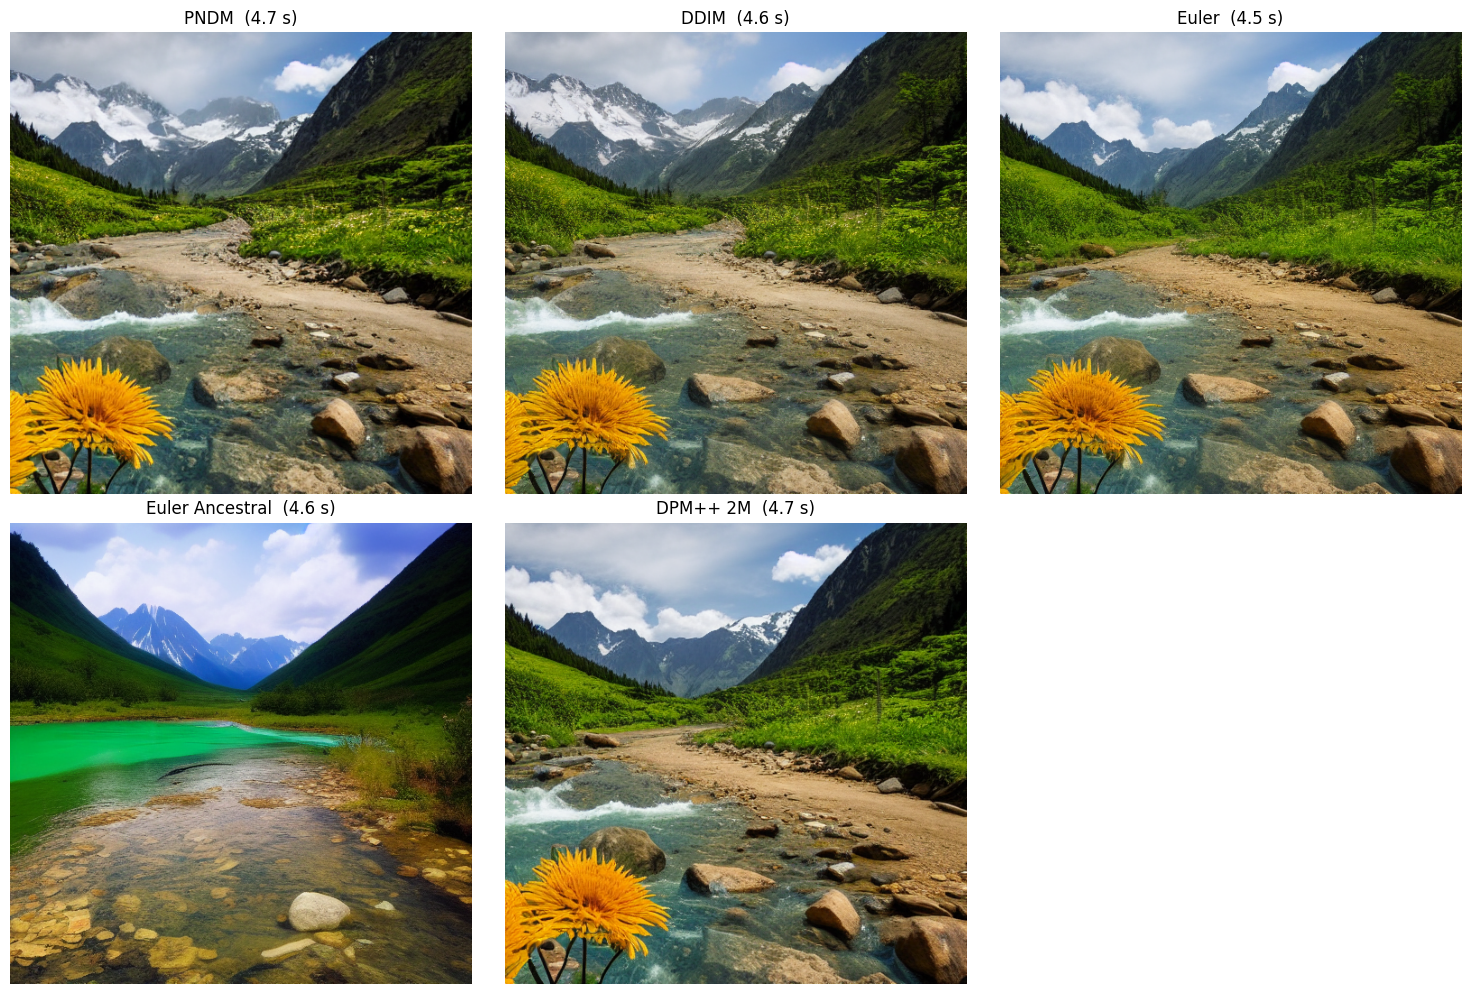

In [8]:
# ---------------------------------------------------------------------
# CELL 9: Experiment 3 - Effect of SAMPLING METHOD (scheduler)
# (steps = 30 and guidance = 7.5 stay the same, only scheduler changes)
# ---------------------------------------------------------------------
# A dictionary: name -> scheduler class
schedulers = {
    "PNDM": PNDMScheduler,
    "DDIM": DDIMScheduler,
    "Euler": EulerDiscreteScheduler,
    "Euler Ancestral": EulerAncestralDiscreteScheduler,
    "DPM++ 2M": DPMSolverMultistepScheduler,
}

images = []
titles = []

for name in schedulers:
    # Build the chosen scheduler and plug it into the pipeline
    pipe.scheduler = schedulers[name].from_config(scheduler_config)
    img, sec = generate(prompt)               # same steps and guidance for all
    images.append(img)
    titles.append(name + "  (" + str(round(sec, 1)) + " s)")

show_images(images, titles)

# Observation: PNDM, DDIM, Euler and DPM++ give almost the same image
# (they are deterministic). Euler Ancestral gives a different image because
# it adds fresh random noise at every step.
# Time taken is almost equal for all, because the model (U-Net) does the heavy work.

## Conclusion

The experiments show that Stable Diffusion can generate images from text prompts, and that its output depends on the settings used.

- Increasing the number of inference steps can improve image detail, but also increases generation time. Beyond a certain point, extra steps may provide only small visual improvements.
- Guidance scale controls how closely the image follows the prompt. Lower values allow more variation, while higher values can make the output adhere more strongly to the description.
- Different schedulers can produce different images and generation times, even when the prompt and other settings stay the same.

The most suitable settings depend on the desired balance between image quality, prompt adherence, and speed.